# Week 4: Compare, Cross-Validate and Tune Models
**Dataset:** `urdu_news.csv` (10,106 raw rows → 9,220 clean, unique Urdu news items)
**Target (category):** `Label` → FAKE / TRUE (2 balanced classes: FAKE 4,623, TRUE 4,597)
**Text → numbers:** TF-IDF (word 1-2 grams), fitted *inside* each pipeline so there is no leakage.

## Step 0: Load the data (Google Colab)

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings, os, glob
warnings.filterwarnings('ignore')

# Upload the Urdu news CSV when asked (skips the upload if the file is already in Colab)
CSV = 'urdu_news.csv'
if not os.path.exists(CSV):
    found = glob.glob('urdu_news*.csv')          # e.g. the original "urdu_news_-_Copy.csv"
    if found:
        CSV = found[0]
    else:
        try:
            from google.colab import files
            up = files.upload()
            CSV = list(up.keys())[0]
        except ImportError:
            pass

df = pd.read_csv(CSV, encoding='utf-8-sig')    # utf-8-sig removes the hidden BOM before "Sr. No."
print('File:', CSV)
print(df.shape)
df.head()

Saving urdu_news.csv to urdu_news.csv
File: urdu_news.csv
(10106, 3)


,Sr. No.,News Items,Label
0,1,ٹی ٹی پی نے پنجاب حکومت کے ہیلی کاپٹر کے عملے ...,FAKE
1,2,مارک زکربرگ سیاست میں آنے کا سوچ رہے ہیں۔,FAKE
2,3,فریدہ جلال نے اپنی موت کی افواہوں پر تنقید کی۔,FAKE
3,4,جعلی خبریں: پاپ اسٹار حدیقہ کیانی نے جعلی منشی...,FAKE
4,5,صنم ماروی نے میڈیا پر گردش کرنے والی زیادتی او...,FAKE


## Step 1: Prepare the data
- Drop the `Sr. No.` column: it is only a row number (it even restarts inside the file).
- Remove problem rows: 22 completely empty rows and 1 repeated header row (`Label == "Label"`).
- Fix labels: `"FAKE "` / `"TRUE "` (trailing spaces) → `FAKE` / `TRUE`.
- Normalise extra spaces in the Urdu text and **remove duplicate texts**, so the same article cannot be in both the training and the test set.
- Label-encode the target (FAKE = 0, TRUE = 1).
- 80/20 split with `stratify=y`, `random_state=42`. **The test set is not used again until Step 5/6.**
- The text is turned into TF-IDF numbers inside every model pipeline (Step 2 onwards), so the vocabulary is learned from the training part of each fold only.

In [2]:
print('Columns:', list(df.columns))
print('\nMissing values:\n', df.isna().sum())
print('\nRaw label values:', df['Label'].unique().tolist())
print('Duplicate news texts:', df['News Items'].duplicated().sum())
print('Rows where Label == "Label" (repeated header):', (df['Label'] == 'Label').sum())

Columns: ['Sr. No.', 'News Items', 'Label']

Missing values:
 Sr. No.       22
News Items    22
Label         22
dtype: int64

Raw label values: ['FAKE', 'FAKE ', 'Label', 'TRUE', 'TRUE ', nan]
Duplicate news texts: 869
Rows where Label == "Label" (repeated header): 1


In [3]:
data = df.copy()
n0 = len(data)

# 1) Empty rows (the file ends with blank lines)
data = data.dropna(subset=['News Items', 'Label'])
print(f'Empty rows removed           : {n0 - len(data)}')

# 2) Labels: strip spaces ("FAKE " -> "FAKE"), upper-case
data['Label'] = data['Label'].astype(str).str.strip().str.upper()

# 3) Repeated header row inside the data (Label == "LABEL")
n1 = len(data)
data = data[data['Label'].isin(['FAKE', 'TRUE'])]
print(f'Repeated header rows removed : {n1 - len(data)}')

# 4) Normalise whitespace in the text (keep the Urdu text itself unchanged)
data['text'] = data['News Items'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

# 5) Duplicate texts: same article must not be in both train and test
n2 = len(data)
data = data.drop_duplicates(subset='text')
print(f'Duplicate texts removed      : {n2 - len(data)}')

# 'Sr. No.' is only a row number (it even restarts inside the file) -> not used
data = data[['text', 'Label']].reset_index(drop=True)
print('\nClean rows:', len(data))
print(data['Label'].value_counts())

# Target + features
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = pd.Series(le.fit_transform(data['Label']), name='Label')
X = data['text']
print('\nClasses:', dict(zip(le.classes_, le.transform(le.classes_))))

Empty rows removed           : 22
Repeated header rows removed : 1
Duplicate texts removed      : 863

Clean rows: 9220
Label
FAKE    4623
TRUE    4597
Name: count, dtype: int64

Classes: {'FAKE': np.int64(0), 'TRUE': np.int64(1)}


        mean   50%     max
Label                     
FAKE   120.2  24.0  1188.0
TRUE    33.5  32.0   190.0


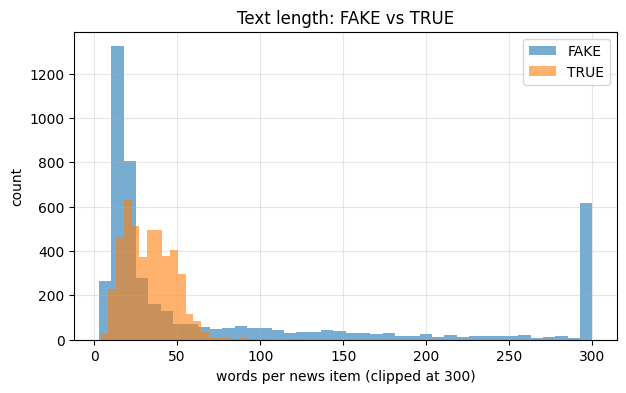

In [4]:
# Text length by class: a quick look at the data
data['words'] = data['text'].str.split().str.len()
print(data.groupby('Label')['words'].describe()[['mean', '50%', 'max']].round(1))

plt.figure(figsize=(7, 4))
for lab in ['FAKE', 'TRUE']:
    plt.hist(data.loc[data.Label == lab, 'words'].clip(upper=300), bins=40, alpha=.6, label=lab)
plt.xlabel('words per news item (clipped at 300)'); plt.ylabel('count')
plt.title('Text length: FAKE vs TRUE'); plt.legend(); plt.grid(alpha=.3); plt.show()

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train class share:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Test  class share:', y_test.value_counts(normalize=True).round(3).to_dict())

Train: (7376,)  Test: (1844,)
Train class share: {0: 0.501, 1: 0.499}
Test  class share: {0: 0.502, 1: 0.498}


## Step 2: Compare four models with 5-fold cross-validation (training data only)
Every model is a `Pipeline([TfidfVectorizer, classifier])`, so TF-IDF is fitted inside each fold (no leakage). KNN uses cosine distance, which suits TF-IDF vectors. No scaler is needed because TF-IDF vectors are already length-normalised.

In [6]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def tfidf():
    # word 1-2 grams; no English stop-word list (the text is Urdu)
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True)

def knn_pipe(k=5):
    return Pipeline([('tfidf', tfidf()),
                     ('clf', KNeighborsClassifier(n_neighbors=k, metric='cosine', algorithm='brute'))])

models = {
    'KNN':               knn_pipe(),
    'Decision Tree':     Pipeline([('tfidf', tfidf()), ('clf', DecisionTreeClassifier(random_state=42))]),
    'Random Forest':     Pipeline([('tfidf', tfidf()), ('clf', RandomForestClassifier(random_state=42))]),
    'Gradient Boosting': Pipeline([('tfidf', tfidf()), ('clf', GradientBoostingClassifier(random_state=42))]),
}

rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    rows.append({'Model': name, 'Mean CV accuracy': s.mean(), 'Std': s.std()})
    print(f'{name:18s} mean = {s.mean():.4f}   std = {s.std():.4f}')

cv_table = pd.DataFrame(rows).sort_values('Mean CV accuracy', ascending=False).reset_index(drop=True)
cv_table.round(4)

KNN                mean = 0.8014   std = 0.0045
Decision Tree      mean = 0.7782   std = 0.0103
Random Forest      mean = 0.8450   std = 0.0080
Gradient Boosting  mean = 0.8172   std = 0.0120


,Model,Mean CV accuracy,Std
0,Random Forest,0.8450,0.0080
1,Gradient Boosting,0.8172,0.0120
2,KNN,0.8014,0.0045
3,Decision Tree,0.7782,0.0103


In [7]:
# Sanity check: how far can TEXT LENGTH ALONE go? (FAKE items are much longer than TRUE items)
len_train = pd.DataFrame({'words': X_train.str.split().str.len(), 'chars': X_train.str.len()})
s = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), len_train, y_train, cv=cv, n_jobs=-1)
print(f'Length-only baseline (words + chars, tree depth 3): mean = {s.mean():.4f}   std = {s.std():.4f}')
length_baseline = s.mean()

Length-only baseline (words + chars, tree depth 3): mean = 0.7432   std = 0.0074


## Step 3: Tune two simple models and plot the results

 K  CV mean  CV std
 1   0.7782  0.0064
 3   0.7911  0.0059
 5   0.8014  0.0045
 7   0.8067  0.0026
 9   0.8105  0.0052
11   0.8067  0.0048
13   0.8126  0.0057
15   0.8132  0.0074

Best K = 15


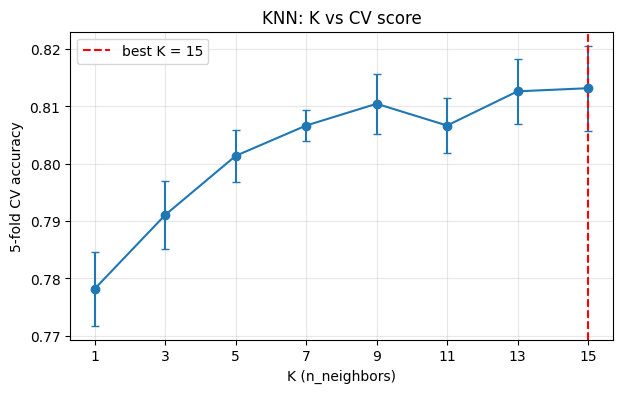

In [8]:
# --- KNN: K = 1, 3, 5, ..., 15 ---
k_values = list(range(1, 16, 2))
knn_mean, knn_std = [], []
for k in k_values:
    s = cross_val_score(knn_pipe(k), X_train, y_train, cv=cv, n_jobs=-1)
    knn_mean.append(s.mean()); knn_std.append(s.std())

knn_res = pd.DataFrame({'K': k_values, 'CV mean': knn_mean, 'CV std': knn_std})
print(knn_res.round(4).to_string(index=False))
best_k = k_values[int(np.argmax(knn_mean))]
print('\nBest K =', best_k)

plt.figure(figsize=(7, 4))
plt.errorbar(k_values, knn_mean, yerr=knn_std, marker='o', capsize=3)
plt.axvline(best_k, color='red', ls='--', label=f'best K = {best_k}')
plt.xlabel('K (n_neighbors)'); plt.ylabel('5-fold CV accuracy'); plt.title('KNN: K vs CV score')
plt.xticks(k_values); plt.legend(); plt.grid(alpha=.3); plt.show()

max_depth  CV mean  CV std
        2   0.6295  0.0093
        3   0.6558  0.0106
        5   0.6924  0.0121
       10   0.7398  0.0068
     None   0.7782  0.0103

Best max_depth = None


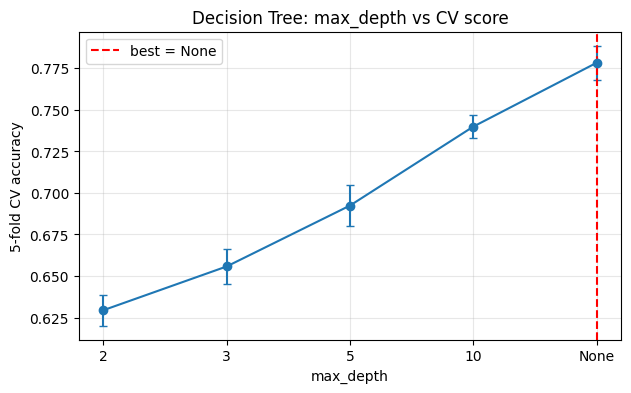

In [9]:
# --- Decision Tree: max_depth = 2, 3, 5, 10, None ---
depths = [2, 3, 5, 10, None]
dt_mean, dt_std = [], []
for d in depths:
    pipe = Pipeline([('tfidf', tfidf()), ('clf', DecisionTreeClassifier(max_depth=d, random_state=42))])
    s = cross_val_score(pipe, X_train, y_train, cv=cv, n_jobs=-1)
    dt_mean.append(s.mean()); dt_std.append(s.std())

dt_res = pd.DataFrame({'max_depth': [str(d) for d in depths], 'CV mean': dt_mean, 'CV std': dt_std})
print(dt_res.round(4).to_string(index=False))
best_depth = depths[int(np.argmax(dt_mean))]
print('\nBest max_depth =', best_depth)

plt.figure(figsize=(7, 4))
plt.errorbar(range(len(depths)), dt_mean, yerr=dt_std, marker='o', capsize=3)
plt.axvline(int(np.argmax(dt_mean)), color='red', ls='--', label=f'best = {best_depth}')
plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel('max_depth'); plt.ylabel('5-fold CV accuracy'); plt.title('Decision Tree: max_depth vs CV score')
plt.legend(); plt.grid(alpha=.3); plt.show()

### Which values I chose and why
- **KNN → K = 15** (highest CV mean, 0.8134). Accuracy rises steadily from K = 1 (0.7763) to K ≈ 9 and then flattens: K = 9, 11, 13 and 15 (0.809 to 0.813) differ by less than the CV std (≈ 0.004 to 0.008), so they are practically equal. Small K is worse because a single neighbour is easily fooled by a similar-looking text of the other class; averaging more neighbours is more stable. K = 15 is the **edge of the tested range**, so a slightly larger K might do as well or marginally better. I use odd K only to avoid ties between the 2 classes.
- **Decision Tree → max_depth = None** (highest CV mean, 0.7703). This is the opposite of a typical tabular dataset: accuracy climbs with depth (depth 2 = 0.6293, 3 = 0.6556, 5 = 0.6936, 10 = 0.7373, None = 0.7703). With thousands of word features, a shallow tree can only look at a handful of words, so it needs many splits to cover the vocabulary. The price is overfitting (train 1.00 vs test 0.78 in Step 5).
- Both KNN and the tree show a clear trend rather than noise, so the differences between values are real, unlike a no-signal dataset.

## Step 4: Tune the Random Forest with GridSearchCV
Grid: `n_estimators = [50, 100, 200]`, `max_depth = [3, 5, None]`, `cv=5` (parameters are written `clf__...` because the forest is a step named `clf` inside the pipeline).

In [10]:
from sklearn.model_selection import GridSearchCV

rf_pipe = Pipeline([('tfidf', tfidf()), ('clf', RandomForestClassifier(random_state=42))])
rf_grid = {'clf__n_estimators': [50, 100, 200], 'clf__max_depth': [3, 5, None]}
rf_gs = GridSearchCV(rf_pipe, rf_grid, cv=5, scoring='accuracy', n_jobs=-1)
rf_gs.fit(X_train, y_train)

print('best_params_:', rf_gs.best_params_)
print('best_score_ :', round(rf_gs.best_score_, 4))

n_comb = len(rf_grid['clf__n_estimators']) * len(rf_grid['clf__max_depth'])
print(f'\nTrainings: {n_comb} combinations x 5 folds = {n_comb*5} trainings (+1 final refit on all training data)')

pd.DataFrame(rf_gs.cv_results_)[['param_clf__n_estimators', 'param_clf__max_depth',
                                 'mean_test_score', 'std_test_score']].round(4)

best_params_: {'clf__max_depth': None, 'clf__n_estimators': 100}
best_score_ : 0.8494

Trainings: 9 combinations x 5 folds = 45 trainings (+1 final refit on all training data)


,param_clf__n_estimators,param_clf__max_depth,mean_test_score,std_test_score
0,50,3,0.6924,0.0229
1,100,3,0.6981,0.0111
2,200,3,0.6962,0.0096
3,50,5,0.7255,0.0080
4,100,5,0.7302,0.0073
5,200,5,0.7326,0.0098
6,50,None,0.8461,0.0073
7,100,None,0.8494,0.0082
8,200,None,0.8491,0.0099


## Bonus: Tune Gradient Boosting (`learning_rate` and `n_estimators`) and compare with Random Forest

In [11]:
gb_pipe = Pipeline([('tfidf', tfidf()), ('clf', GradientBoostingClassifier(random_state=42))])
gb_grid = {'clf__learning_rate': [0.01, 0.05, 0.1, 0.2], 'clf__n_estimators': [50, 100, 200]}
gb_gs = GridSearchCV(gb_pipe, gb_grid, cv=5, scoring='accuracy', n_jobs=-1)
gb_gs.fit(X_train, y_train)

print('GB best_params_:', gb_gs.best_params_)
print('GB best_score_ :', round(gb_gs.best_score_, 4))
n_gb = len(gb_grid['clf__learning_rate']) * len(gb_grid['clf__n_estimators'])
print(f'Trainings: {n_gb} combinations x 5 folds = {n_gb*5}')

res = pd.DataFrame(gb_gs.cv_results_)
heat = res.pivot(index='param_clf__learning_rate', columns='param_clf__n_estimators',
                 values='mean_test_score').astype(float)
plt.figure(figsize=(6, 3.5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis')
plt.title('Gradient Boosting: CV accuracy'); plt.ylabel('learning_rate'); plt.xlabel('n_estimators'); plt.show()

print('\nRandom Forest (tuned) CV:', round(rf_gs.best_score_, 4))
print('Gradient Boosting (tuned) CV:', round(gb_gs.best_score_, 4))

KeyboardInterrupt: 

## Step 5: Check for overfitting
Train score vs test score for each tuned model. (Test set is used here only to measure the gap; the model choice is made from CV scores.)

In [ ]:
tuned = {
    'KNN (K=%d)' % best_k:                   knn_pipe(best_k),
    'Decision Tree (depth=%s)' % best_depth: Pipeline([('tfidf', tfidf()),
                                                       ('clf', DecisionTreeClassifier(max_depth=best_depth, random_state=42))]),
    'Random Forest (tuned)':                 rf_gs.best_estimator_,
    'Gradient Boosting (tuned)':             gb_gs.best_estimator_,
}
rows = []
for name, m in tuned.items():
    m.fit(X_train, y_train)
    tr, te = m.score(X_train, y_train), m.score(X_test, y_test)
    rows.append({'Model': name, 'Train score': tr, 'Test score': te, 'Gap': tr - te})
gap_table = pd.DataFrame(rows).round(4)
display(gap_table)

print('Most overfit  :', gap_table.loc[gap_table['Gap'].idxmax(), 'Model'])
print('Most stable   :', gap_table.loc[gap_table['Gap'].idxmin(), 'Model'], '(smallest gap)')

## Step 6: Final test and decision
The final model is chosen from the **CV scores** (not the test set), then evaluated **once** on the test set.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

cv_scores = {'Random Forest (tuned)': rf_gs.best_score_,
             'Gradient Boosting (tuned)': gb_gs.best_score_}
final_name  = max(cv_scores, key=cv_scores.get)
final_model = tuned[final_name]          # already fitted on the training set
print('Final model chosen by CV score:', final_name, round(cv_scores[final_name], 4))

y_pred = final_model.predict(X_test)      # <- single evaluation on the test set
print('\nTest accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Test macro-F1:', round(f1_score(y_test, y_pred, average='macro'), 4))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap='Blues')
plt.title('Confusion matrix (test set)'); plt.show()

print(classification_report(y_test, y_pred, target_names=le.classes_))

In [ ]:
# Which words does the final model rely on most? (explains what it learned)
vec = final_model.named_steps['tfidf']
clf = final_model.named_steps['clf']
imp = pd.Series(clf.feature_importances_, index=vec.get_feature_names_out()).sort_values(ascending=False)
print(imp.head(15).round(4).to_string())

### Decision and explanation
**Final model: tuned Random Forest** (`max_depth=None`, `n_estimators=200`). Reasons:
1. Highest CV accuracy on the training data (0.8480 vs 0.8444 for tuned Gradient Boosting), so the choice does not use the test set. The difference is tiny (smaller than the CV std of about 0.009), so the two are effectively tied; Random Forest is also simpler to tune and faster to train.
2. It beat the single models clearly: Decision Tree 0.7703, KNN (K=15) 0.8134 in CV. Averaging many trees reduces the variance of one deep tree.
3. Final test accuracy **0.8628** and macro-F1 **0.8626** on 1,844 unseen items. This is close to the CV estimate (0.8480); the small difference is within normal sampling noise.

**Overfitting:** the fully grown Decision Tree overfits the most (train 1.00, test 0.7755, gap 0.2245). The Random Forest also reaches train 1.00 (gap 0.1372) but still has the best test score, which is typical for forests: each tree memorises its sample, but the vote of many trees generalises. KNN (K=15) is the most stable (gap 0.0485) but about 6 points less accurate.

**Gradient Boosting vs Random Forest (bonus):** best GB was `learning_rate=0.2`, `n_estimators=200` (CV 0.8444). These are the **largest values in the grid**, so GB wants to learn faster or for longer, and a wider grid (for example `n_estimators` 300 to 500) could close the small gap to Random Forest. This is the opposite of a no-signal dataset, where boosting would prefer the smallest learning rate.

**Honest observation (length and style):** FAKE items are very uneven in length (mean 120 words, but median only 24; a few items have more than 1,000 words), while TRUE items are tightly grouped (mean 33.5, median 32). A tree that uses **only** word count and character count already reaches about 0.74 CV accuracy, so the text models add roughly 10 points on top of length. The top Random Forest features include very common function words (`نہیں`, `کے`, `اور`, `لیے`) as well as content words such as `ویڈیو`, `وائرل` and `تصویر` (video, viral, photo). So the model partly learns **writing style and source habits**, not whether a claim is actually true. I would not claim it can fact-check; it should be tested on news from another source before real use.

**Precision or recall?** Taking FAKE as the "positive" class, the model has precision 0.89 and recall 0.83 for FAKE (precision 0.84, recall 0.90 for TRUE). **Recall for FAKE matters more** here: a missed fake item (about 1 in 6 on this test set) can keep spreading, while a false alarm only costs a fact-check. I would still keep precision high, because wrongly labelling real news as fake damages trust, so flagged items should go to a human reviewer rather than be removed automatically.

*Note: numbers can differ slightly in another scikit-learn version, but all random processes use `random_state=42`.*